# Conditioned entity-ranking comparison

Compare SimBench original, SimBench bounded robust-z, and Model FR for the same condition, held-out reference entity, and candidate pool. For every reference, pairwise agreement is calculated on the candidates scored by all three methods. The bounded robust-z profile is fitted on different reference queries; candidate entities may still overlap between the training and evaluation pools.

The original scorer drops unavailable evidence and uses its saved effective weights. Robust-z uses the profile's missing-evidence policy and equal nominal signal weights, so differences can reflect both normalization and missing-evidence handling. Agreement shows how similarly rankings behave; human entity comparisons are needed to assess relevance.

In [1]:
from pathlib import Path
from functools import lru_cache
import importlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

HERE = Path.cwd().resolve()
REPO = next((p for p in (HERE, *HERE.parents) if (p / 'conditions/rel-amazon/conditions.jsonl').is_file()), None)
if REPO is None:
    raise RuntimeError('Open the notebook from the Similarity_benchmark repository.')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from scripts.compare_entity_rankings import load_run
from src.datasets.local_relbench_dataset import LocalRelBenchDataset
from src.similarity import conditioned_analysis as _conditioned_analysis
from src.similarity import experimental_scoring as _experimental_scoring
# Notebook kernels keep imported modules cached across edits; reload the current on-disk code.
importlib.reload(_experimental_scoring)
importlib.reload(_conditioned_analysis)
BASELINE_LABEL = 'Model FR'
METHODS = (*_conditioned_analysis.METHODS[:2], BASELINE_LABEL)
load_condition = _conditioned_analysis.load_condition
shared_scores = _conditioned_analysis.shared_scores
compare_condition = _conditioned_analysis.compare_condition
score_components = _experimental_scoring.score_components

# Change these paths if the experiments were saved elsewhere.
RUN_DIR = REPO / 'results/rel-amazon/similarity/conditioned-comparison'
ROBUST_DIR = REPO / 'results/rel-amazon/similarity/experimental-scoring-bounded-robust-z'
TOP_N = 10
manifest_path = RUN_DIR / 'experiment.json'
if not manifest_path.is_file():
    raise FileNotFoundError(f'No experiment found at {manifest_path}. Run the experiment command first.')
manifest = json.loads(manifest_path.read_text())
config = manifest['config']
comparison_paths = sorted(RUN_DIR.glob('condition-*/comparison.jsonl'))

def _baseline_path(condition_id):
    folder = RUN_DIR / str(condition_id)
    known_files = {'simbench.jsonl', 'comparison.jsonl'}
    candidates = [path for path in folder.glob('*.jsonl') if path.name not in known_files]
    if len(candidates) != 1:
        raise FileNotFoundError(f'Expected one baseline ranking file in {folder}; found {len(candidates)}.')
    return candidates[0]

@lru_cache(maxsize=1)
def matched_condition(cid):
    return load_condition(RUN_DIR, ROBUST_DIR, str(cid), manifest,
                          baseline_filename=_baseline_path(str(cid)).name, baseline_label=METHODS[2])

records, unavailable = [], {}
for cid in sorted(manifest['conditions']):
    try:
        records.extend(compare_condition(cid, matched_condition(cid), int(config['top_k'])))
        print(f'{cid}: loaded held-out rankings', flush=True)
    except (OSError, ValueError, KeyError, TypeError) as error:
        unavailable[cid] = str(error)
        print(f'{cid}: skipped — {error}', flush=True)
columns = ['condition_id', 'entity_table', 'query_entity_id', 'method_a', 'method_b',
           'candidates', 'shared_scored', 'spearman', 'top_k', 'left_top_size',
           'right_top_size', 'top_intersection', 'top_jaccard']
three_way = pd.DataFrame(records, columns=columns)
comparisons = three_way[(three_way['method_a'] == 'SimBench original') &
                        (three_way['method_b'] == 'Model FR')].copy()
print(f"Completed three-method conditions: {three_way['condition_id'].nunique()}/{len(manifest['conditions'])} | comparison cutoff: {config['top_k']}")

condition-001: loaded held-out rankings
condition-002: loaded held-out rankings
condition-003: loaded held-out rankings
condition-004: loaded held-out rankings
condition-005: loaded held-out rankings
condition-006: loaded held-out rankings
condition-007: loaded held-out rankings
condition-008: loaded held-out rankings
condition-009: loaded held-out rankings
condition-010: loaded held-out rankings
condition-011: loaded held-out rankings
condition-012: loaded held-out rankings
condition-013: loaded held-out rankings
condition-014: loaded held-out rankings
condition-015: loaded held-out rankings
Completed three-method conditions: 15/15 | comparison cutoff: 10


## Experiment configuration and coverage

The same sampled references and candidate pool are used for every condition targeting the same table. Each reference is excluded from its own candidate ranking. The comparisons below use the bounded robust-z profile's held-out references and the same three-way set of scored candidates. A condition is skipped if its profiles or candidate pools do not match.

In [2]:
display(pd.DataFrame([
    {'entity table': table, 'all entities': values['entity_count'],
     'candidate pool': len(values['candidate_ids']), 'sampled references': len(values['query_ids']),
     'entity ID type': values['entity_id_kind']}
    for table, values in manifest['cohorts'].items()
]).set_index('entity table'))
print('Signal discovery:', config['discovery_results'])
if 'min_utility_score' in config:
    print('Signal selection: discovery utility ≥', config['min_utility_score'], '/ 10')
else:
    print('Signals per condition:', config.get('top_signals', 'unknown'))
print('Weight-generation settings: reasoning effort:', config['reasoning_effort'], '| seed:', config['seed'])
status = pd.DataFrame([{'condition': cid, 'entity table': table,
                       'Model FR': _baseline_path(cid).is_file(),
                       'SimBench': (RUN_DIR / cid / 'simbench.jsonl').exists(),
                       'bounded robust-z': (ROBUST_DIR / cid / 'profile.json').exists() and (ROBUST_DIR / cid / 'pairs.jsonl').exists(),
                       'matched held-out references': three_way.loc[(three_way['condition_id'] == cid) & (three_way['method_a'] == METHODS[0]) & (three_way['method_b'] == METHODS[1]), 'query_entity_id'].nunique(),
                       'selected signals': len(manifest.get('selected_signals', {}).get(cid, [])) if 'selected_signals' in manifest else None}
                      for cid, table in manifest['condition_tables'].items()])
display(status.set_index('condition'))
if unavailable:
    print('Unavailable conditions:', unavailable)

,all entities,candidate pool,sampled references,entity ID type
entity table,,,,
customer,43948,1000,50,primary_key
product,500,500,50,primary_key
review,50000,1000,50,row_position


Signal discovery: /storage/lcostes/Similarity_benchmark/results/rel-amazon/discovery/catalog-views/catalog-rank-gpt-6-luna-utility-0-10-high-path-aware.jsonl
Signal selection: discovery utility ≥ 5 / 10
Weight-generation settings: reasoning effort: none | seed: 42


,entity table,Model FR,SimBench,bounded robust-z,matched held-out references,selected signals
condition,,,,,,
condition-001,product,True,True,True,25,5
condition-002,review,True,True,True,25,3
condition-003,product,True,True,True,25,2
condition-004,review,True,True,True,25,3
condition-005,customer,True,True,True,25,2
condition-006,product,True,True,True,25,4
condition-007,product,True,True,True,25,2
condition-008,review,True,True,True,25,3
condition-009,product,True,True,True,25,4


## Agreement by condition

Every pair of methods uses the same held-out references and candidates scored by **all three** methods. Spearman compares rank order with average ranks for ties. Top-k Jaccard compares the top sets, including all candidates tied at the cutoff. Coverage reports the fraction of each original candidate pool that all three methods score. Agreement does not establish relevance.

In [ ]:
if three_way.empty:
    print('No matched three-method comparisons are available.')
else:
    three_way['shared scored fraction'] = three_way['shared_scored'] / three_way['candidates'].where(three_way['candidates'] > 0)
    overall = (three_way.groupby(['method_a', 'method_b'], as_index=False)
               .agg(references=('query_entity_id', 'size'),
                    conditions=('condition_id', 'nunique'),
                    scored_references=('shared_scored', lambda values: int((values > 0).sum())),
                    mean_spearman=('spearman', 'mean'),
                    mean_top_jaccard=('top_jaccard', 'mean'),
                    mean_shared_fraction=('shared scored fraction', 'mean')))
    display(Markdown('### Overall across matched held-out references'))
    display(overall.round(3))
    by_condition = (three_way.groupby(['condition_id', 'method_a', 'method_b'], as_index=False)
                    .agg(mean_spearman=('spearman', 'mean'), mean_top_jaccard=('top_jaccard', 'mean')))
    ids = sorted(by_condition['condition_id'].unique())
    y = np.arange(len(ids))
    pairs = [(METHODS[0], METHODS[1]), (METHODS[0], METHODS[2]), (METHODS[1], METHODS[2])]
    colors = ['#4c78a8', '#f58518', '#54a24b']
    fig, axes = plt.subplots(1, 2, figsize=(18, max(7, len(ids) * .58)), sharey=True, layout='constrained')
    for i, ((a, b), color) in enumerate(zip(pairs, colors)):
        view = by_condition[(by_condition['method_a'] == a) & (by_condition['method_b'] == b)].set_index('condition_id').reindex(ids)
        label = f'{a} vs {b}'
        for ax, metric in zip(axes, ['mean_spearman', 'mean_top_jaccard']):
            ax.barh(y + (i - 1) * .25, view[metric], height=.24, color=color, label=label)
    axes[0].set_yticks(y, labels=ids); axes[0].invert_yaxis()
    axes[0].set_xlim(-1, 1); axes[0].axvline(0, color='black', linewidth=.7)
    axes[1].set_xlim(0, 1)
    axes[0].set_title('Mean Spearman rank correlation')
    axes[1].set_title(f"Mean top-{config['top_k']} Jaccard overlap")
    for ax in axes: ax.grid(axis='x', alpha=.2)
    axes[1].legend(loc='lower right', fontsize=8)
    display(fig); plt.close(fig)

## Evidence coverage in top results

These saved summaries show the average share of signal evidence available for each method’s own top results on held-out references. They use each SimBench variant’s available candidates; the three-way agreement above uses their common scored candidates. Lower coverage can indicate that a result relies on less observed evidence.

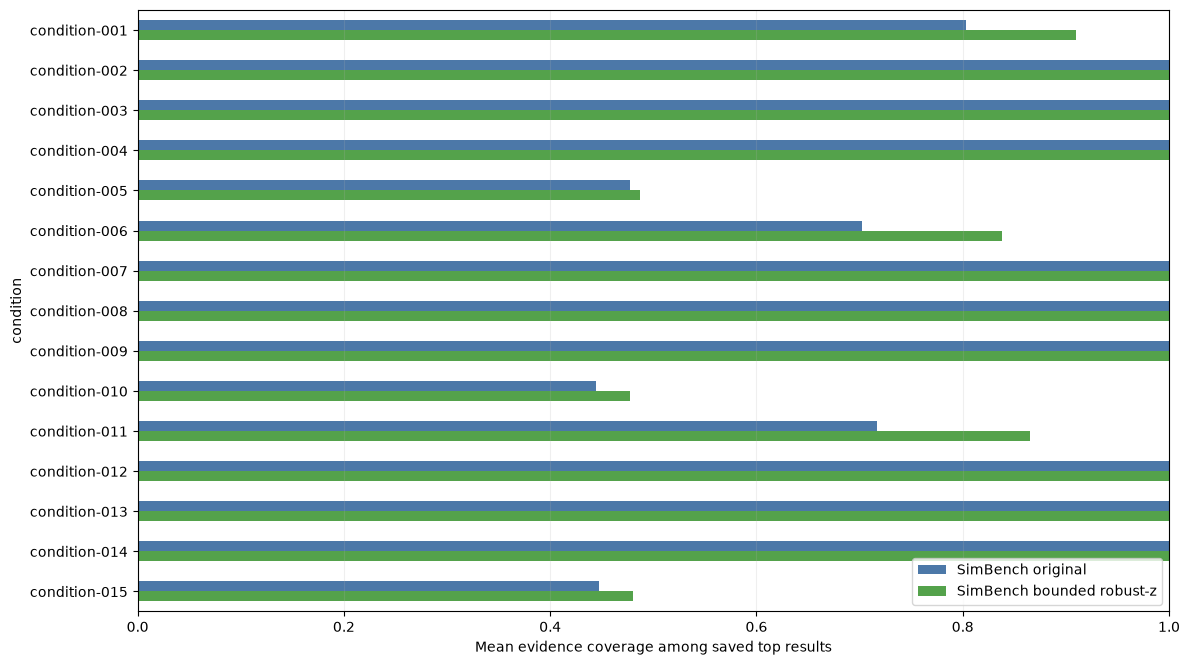

,SimBench original,SimBench bounded robust-z
condition,,
condition-001,0.803,0.910
condition-002,1.000,1.000
condition-003,1.000,1.000
condition-004,1.000,1.000
condition-005,0.478,0.487
condition-006,0.702,0.838
condition-007,1.000,1.000
condition-008,1.000,1.000
condition-009,1.000,1.000


In [4]:
coverage_rows = []
for cid in sorted(three_way['condition_id'].unique()):
    path = ROBUST_DIR / cid / 'summary.json'
    if path.exists():
        item = json.loads(path.read_text())
        coverage_rows.append({'condition': cid, 'SimBench original': item.get('baseline_top_coverage'),
                              'SimBench bounded robust-z': item.get('experimental_top_coverage')})
coverage_summary = pd.DataFrame(coverage_rows)
if coverage_summary.empty:
    print('No saved evidence-coverage summaries are available.')
else:
    view = coverage_summary.set_index('condition').sort_index()
    ax = view.plot.barh(figsize=(12, max(6, len(view) * .45)), color=['#4c78a8', '#54a24b'])
    ax.set_xlim(0, 1); ax.invert_yaxis(); ax.set_xlabel('Mean evidence coverage among saved top results')
    ax.grid(axis='x', alpha=.2); plt.tight_layout(); display(ax.figure); plt.close(ax.figure)
    display(view.round(3))

## Browse a condition and reference entity

The table shows candidates appearing in any method's top results, restricted to candidates scored by all three methods. Tied scores share a rank. Scores are on different scales; compare ranks rather than raw score values across methods.

In [5]:
if comparisons.empty:
    print('No matched query comparisons are available yet.')
else:
    dataset = LocalRelBenchDataset(Path(config['dataset_root']))
    @lru_cache(maxsize=3)
    def entity_table(table):
        frame = dataset.get_table(table).to_pandas()
        key = dataset.get_primary_key(table)
        frame.index = frame[key].map(str) if key else frame.index.map(str)
        return frame

    def brief(value, limit=180):
        text = str(value).replace('\n', ' ')
        return text if len(text) <= limit else text[:limit] + '…'

    def entity_summary(table, entity_id):
        frame = entity_table(table)
        if str(entity_id) not in frame.index: return '(entity not found)'
        row = frame.loc[str(entity_id)]
        fields = {'product': ['title'], 'review': ['summary', 'review_text'],
                  'customer': ['customer_name']}.get(table, [])
        return ' | '.join(f'{field}: {brief(row[field])}' for field in fields if field in row.index)

    condition_picker = widgets.Dropdown(options=sorted(comparisons['condition_id'].unique()), description='Condition:', layout=widgets.Layout(width='95%'))
    query_picker = widgets.Dropdown(description='Reference:', layout=widgets.Layout(width='95%'))
    n_picker = widgets.IntSlider(value=TOP_N, min=1, max=50, description='Top:', continuous_update=False)
    browser = widgets.Output()

    def show_query(*_):
        with browser:
            clear_output(wait=True)
            cid, query = condition_picker.value, query_picker.value
            if cid is None or query is None: return
            table = manifest['condition_tables'][cid]
            try:
                data = matched_condition(cid)
                scores = shared_scores(data['scores'][str(query)])
                ranks = {name: pd.Series(values, dtype=float).rank(method='min', ascending=False) for name, values in scores.items()}
                top = set().union(*(set(rank[rank <= n_picker.value].index) for rank in ranks.values()))
                rows = []
                for candidate in top:
                    row = {'candidate': candidate, 'entity': entity_summary(table, candidate)}
                    for name in METHODS:
                        row[f'{name} rank'] = ranks[name].get(candidate)
                        row[f'{name} score'] = scores[name].get(candidate)
                    row['bounded robust-z evidence coverage'] = data['coverage'][str(query)].get(candidate)
                    rows.append(row)
                result = pd.DataFrame(rows)
                if not result.empty:
                    rank_columns = [f'{name} rank' for name in METHODS]
                    result['best rank'] = result[rank_columns].min(axis=1)
                    result = result.sort_values(['best rank', 'candidate']).drop(columns='best rank')
                display(Markdown(f"**Condition:** {manifest['conditions'][cid]}\n\n**Reference {table} {query}:** {entity_summary(table, query)}"))
                display(result.round(3).reset_index(drop=True))
                chosen_signals = manifest.get('selected_signals', {}).get(cid)
                if chosen_signals:
                    display(Markdown('**SimBench signals selected from discovery**'))
                    display(pd.DataFrame(chosen_signals).rename(columns={'id': 'signal', 'utility_score': 'discovery utility / 10'}))
                selected = three_way[(three_way['condition_id'] == cid) & (three_way['query_entity_id'].astype(str) == str(query))]
                if not selected.empty:
                    display(selected[['method_a', 'method_b', 'spearman', 'top_k', 'top_jaccard', 'shared_scored', 'candidates']].reset_index(drop=True).round(3))
            except (OSError, KeyError, ValueError, TypeError) as error:
                print(f'Could not display this query: {error}')

    def update_queries(*_):
        cid = condition_picker.value
        rows = comparisons[comparisons['condition_id'] == cid]
        options = sorted(rows['query_entity_id'].astype(str).unique())
        query_picker.options = options
        if options and query_picker.value not in options:
            query_picker.value = options[0]
        show_query()

    condition_picker.observe(update_queries, names='value')
    query_picker.observe(show_query, names='value')
    n_picker.observe(show_query, names='value')
    display(widgets.VBox([condition_picker, query_picker, n_picker, browser]))
    update_queries()

## Inspect a chosen rank from each method

Select a condition and held-out reference, then choose a rank independently for each method. Four cards display the reference and selected results with their attributes and score details. Tied candidates at a selected rank are shown together. Bounded robust-z shows each raw score, bounded signal score, score contribution, deviation from the neutral 0.5 signal value, and evidence coverage. A contribution comparison for the selected original and bounded bounded robust-z candidates appears below the cards.


In [6]:
from html import escape
from IPython.display import HTML as _RankHTML

if comparisons.empty:
    print('No matched query comparisons are available yet.')
else:
    _rank_dataset = LocalRelBenchDataset(Path(config['dataset_root']))

    @lru_cache(maxsize=3)
    def _rank_entity_table(table_name):
        frame = _rank_dataset.get_table(table_name).to_pandas()
        primary_key = _rank_dataset.get_primary_key(table_name)
        frame.index = frame[primary_key].map(str) if primary_key else frame.index.map(str)
        return frame

    @lru_cache(maxsize=1)
    def _rank_condition_runs(condition_id):
        return (load_run(_baseline_path(condition_id)),
                load_run(RUN_DIR / condition_id / 'simbench.jsonl'))

    @lru_cache(maxsize=2)
    def _rank_query_component_records(condition_id, query_id):
        records = []
        for method_name in (BASELINE_LABEL, 'SimBench'):
            found = {}
            run_path = _baseline_path(condition_id) if method_name == BASELINE_LABEL else RUN_DIR / condition_id / 'simbench.jsonl'
            with run_path.open(encoding='utf-8') as stream:
                for line in stream:
                    if not line.strip(): continue
                    row = json.loads(line)
                    if str(row.get('query_entity_id')) == str(query_id):
                        found = {str(pair['candidate_entity_id']): pair for pair in row.get('pairs', [])}
                        break
            records.append(found)
        return tuple(records)

    def _rank_component_breakdown(method_name, pair):
        if not pair: return '<p>Saved component details are unavailable for this candidate.</p>'
        components = pair.get('components', [])
        contributions = []
        if method_name == BASELINE_LABEL:
            contributions = [(str(c.get('feature', 'feature')), float(c.get('weighted_score') or 0.0)) for c in components]
        else:
            available = [c for c in components if c.get('score') is not None]
            denominator = sum(float(c.get('effective_weight', c.get('weight', 1.0))) for c in available)
            if denominator:
                contributions = [(str(c.get('signal_id', 'signal')), float(c['score']) *
                                  float(c.get('effective_weight', c.get('weight', 1.0))) / denominator)
                                 for c in available]
        if not contributions: return '<p>No scored components are available for this candidate.</p>'
        contributions.sort(key=lambda item: abs(item[1]), reverse=True)
        rows = ['<div class="simbench-contribution"><b>{}</b><span>{:+.6f} {}</span></div>'.format(
            escape(name), value, '<em>largest contribution</em>' if index == 0 else '')
            for index, (name, value) in enumerate(contributions)]
        return '<details class="simbench-explanation" open><summary>Score contributions</summary>' + ''.join(rows) + '</details>'

    def _rank_robust_details(pair, profile, query_id, candidate):
        if not pair or not pair.get('components'):
            return '<p>Saved signal details are unavailable for this candidate.</p>'
        frame = pd.DataFrame([{'query': str(query_id), 'candidate': str(candidate),
                               'signal': c['signal_id'], 'measure': c['measure'],
                               'raw_score': c.get('score'), 'confidence': c.get('confidence', 1.0),
                               'base_weight': c.get('weight', 1.0)} for c in pair['components']])
        _, scored = score_components(frame, profile)
        rows = []
        for _, component in scored.iterrows():
            raw = component['raw_score']
            raw_text = 'missing' if pd.isna(raw) else f'{raw:.4f}'
            status = 'imputed' if component['imputed'] else 'observed'
            confidence = float(component['usable_confidence'])
            total_weight = float(scored['experimental_weight'].sum())
            contribution = float(component['weighted_score']) / total_weight if total_weight > 0 else 0.0
            neutral_effect = ((float(component['experimental_score']) - 0.5)
                              * float(component['experimental_weight']) / total_weight if total_weight > 0 else 0.0)
            rows.append('<div class="simbench-contribution"><b>{}</b><span>raw {}; bounded score {:.4f}; contribution {:+.6f}; effect vs 0.5 {:+.6f}; {}; confidence {:.0%}</span></div>'.format(
                escape(str(component['signal'])), raw_text, component['experimental_score'], contribution, neutral_effect, status, confidence))
        return ('<details class="simbench-explanation" open>'
                '<summary>Per-signal contributions</summary>' + ''.join(rows) + '</details>')

    def _rank_contribution_map(method_name, pair, profile, query_id, candidate_id):
        if not pair or not pair.get('components'):
            return {}
        if method_name == 'SimBench original':
            available = [component for component in pair['components'] if component.get('score') is not None]
            denominator = sum(float(component.get('effective_weight', component.get('weight', 1.0)))
                              for component in available)
            if denominator <= 0:
                return {}
            return {
                str(component.get('signal_id', 'signal')):
                    float(component['score']) * float(component.get('effective_weight', component.get('weight', 1.0))) / denominator
                for component in available
            }
        frame = pd.DataFrame([{
            'query': str(query_id), 'candidate': str(candidate_id),
            'signal': component['signal_id'], 'measure': component['measure'],
            'raw_score': component.get('score'), 'confidence': component.get('confidence', 1.0),
            'base_weight': component.get('weight', 1.0),
        } for component in pair['components']])
        _, scored = score_components(frame, profile)
        denominator = float(scored['experimental_weight'].sum())
        if denominator <= 0:
            return {}
        return {
            str(component['signal']): float(component['weighted_score']) / denominator
            for _, component in scored.iterrows()
        }

    def _rank_contribution_comparison(candidate_id, sim_pairs, profile, query_id, original_score, robust_score):
        candidate_id = str(candidate_id)
        original = _rank_contribution_map('SimBench original', sim_pairs.get(candidate_id), profile,
                                          query_id, candidate_id)
        robust = _rank_contribution_map('SimBench bounded robust-z', sim_pairs.get(candidate_id), profile,
                                        query_id, candidate_id)
        signal_ids = sorted(original.keys() | robust.keys(),
                            key=lambda signal: (-abs(robust.get(signal, 0.0) - original.get(signal, 0.0)), signal))
        if not signal_ids:
            return f'<p>Contribution comparison unavailable for candidate {escape(candidate_id)}.</p>'
        rows = []
        for signal in signal_ids:
            original_value = f'{original[signal]:+.6f}' if signal in original else '—'
            robust_value = f'{robust[signal]:+.6f}' if signal in robust else '—'
            difference = robust.get(signal, 0.0) - original.get(signal, 0.0)
            rows.append(
                '<tr><td>{}</td><td>{}</td><td>{}</td><td>{:+.6f}</td></tr>'.format(
                    escape(signal), original_value, robust_value, difference)
            )
        original_total = 'unavailable' if original_score is None else f'{float(original_score):+.6f}'
        robust_total = 'unavailable' if robust_score is None else f'{float(robust_score):+.6f}'
        return (
            f'<h4>Candidate {escape(candidate_id)} — original {original_total} · robust-z {robust_total}</h4>'
            '<div style="overflow-x:auto"><table style="border-collapse:collapse;width:100%">'
            '<thead><tr><th>Signal</th><th>Original contribution</th><th>Robust-z contribution</th>'
            '<th>Robust-z − original</th></tr></thead><tbody>' + ''.join(rows) + '</tbody></table></div>'
        )

    def _rank_display_value(value):
        if hasattr(value, 'tolist'): value = value.tolist()
        if isinstance(value, (dict, list, tuple)):
            return json.dumps(value, ensure_ascii=False, indent=2, default=str)
        if value is None: return 'null'
        try:
            if pd.isna(value): return 'null'
        except (TypeError, ValueError):
            pass
        return str(value)

    def _rank_entity_card(table_name, entity_id, heading, score=None, method_rank=None,
                          contribution_html='', evidence_coverage=None):
        frame = _rank_entity_table(table_name)
        entity_id = str(entity_id)
        if entity_id not in frame.index:
            details = '<p>Entity not found in the loaded table.</p>'
        else:
            row = frame.loc[entity_id]
            if isinstance(row, pd.DataFrame): row = row.iloc[0]
            details = ''.join('<div class="simbench-field"><b>{}</b><pre>{}</pre></div>'.format(
                escape(str(column)), escape(_rank_display_value(value))) for column, value in row.items())
        metadata = f'<div class="simbench-meta">Entity ID: <code>{escape(entity_id)}</code>'
        if method_rank is not None: metadata += f' · Rank: {method_rank}'
        if score is not None: metadata += f' · Score: {score:.3g}'
        if evidence_coverage is not None: metadata += f' · Evidence coverage: {evidence_coverage:.1%}'
        metadata += '</div>'
        return '<section class="simbench-card"><h3>{}</h3>{}{}{}</section>'.format(
            escape(heading), metadata, contribution_html, details)

    _rank_condition_ids = sorted(comparisons['condition_id'].astype(str).unique())
    _rank_condition_picker = widgets.Dropdown(
        options=[(f"{cid} — {manifest['conditions'].get(cid, '')}", cid) for cid in _rank_condition_ids],
        description='Condition:', layout=widgets.Layout(width='98%'))
    _rank_query_picker = widgets.Dropdown(description='Reference:', layout=widgets.Layout(width='98%'))
    _rank_pickers = {name: widgets.Dropdown(description=label, layout=widgets.Layout(width='32%'),
                                            style={'description_width': 'initial'})
                     for name, label in ((METHODS[2], 'Model FR rank:'),
                                         (METHODS[0], 'Original rank:'),
                                         (METHODS[1], 'Robust-z rank:'))}
    _rank_output = widgets.Output()
    _rank_state = {'updating': False}

    def _rank_choices(scores):
        series = pd.Series(scores, dtype=float).dropna()
        if series.empty: return []
        ranks = series.rank(method='min', ascending=False).astype(int)
        choices = []
        for rank in sorted(ranks.unique()):
            count = int(ranks.eq(rank).sum())
            choices.append((f"{rank}" + (f" ({count} tied)" if count > 1 else ''), int(rank)))
        return choices

    def _rank_refresh_method_options(*_):
        if _rank_state['updating']: return
        cid, query = _rank_condition_picker.value, _rank_query_picker.value
        if cid is None or query is None: return
        try:
            _rank_state['updating'] = True
            scores = shared_scores(matched_condition(cid)['scores'][str(query)])
            for name, picker in _rank_pickers.items():
                picker.options = _rank_choices(scores[name])
                if picker.options: picker.value = picker.options[0][1]
        except (OSError, KeyError, ValueError) as error:
            with _rank_output: clear_output(wait=True); print(f'Could not load rankings for this reference: {error}')
        finally:
            _rank_state['updating'] = False
        _rank_render_selection()

    def _rank_update_options(*_):
        if _rank_state['updating']: return
        cid = _rank_condition_picker.value
        _rank_state['updating'] = True
        try:
            rows = comparisons[comparisons['condition_id'].astype(str).eq(str(cid))]
            options = sorted(rows['query_entity_id'].astype(str).unique())
            _rank_query_picker.options = options
            if options and _rank_query_picker.value not in options:
                _rank_query_picker.value = options[0]
        finally:
            _rank_state['updating'] = False
        _rank_refresh_method_options()

    def _rank_render_selection(*_):
        if _rank_state['updating']: return
        with _rank_output:
            clear_output(wait=True)
            try:
                cid, query_id = _rank_condition_picker.value, _rank_query_picker.value
                if cid is None or query_id is None: return
                table_name = manifest['condition_tables'][cid]
                data = matched_condition(cid)
                scores = shared_scores(data['scores'][str(query_id)])
                fuse_pairs, sim_pairs = _rank_query_component_records(str(cid), str(query_id))
                ref_card = _rank_entity_card(table_name, query_id, f'Reference · {table_name}')
                def cards_for(method):
                    rank = _rank_pickers[method].value
                    series = pd.Series(scores[method], dtype=float).dropna()
                    if rank is None or series.empty:
                        return f'<section class="simbench-card"><h3>{escape(method)}</h3><p>No candidate at this rank.</p></section>'
                    ranks = series.rank(method='min', ascending=False).astype(int)
                    cards = []
                    for entity_id in ranks.index[ranks.eq(int(rank))]:
                        entity_id = str(entity_id)
                        evidence_coverage = None
                        if method == METHODS[1]:
                            evidence_coverage = data['coverage'][str(query_id)].get(entity_id)
                            detail = _rank_robust_details(sim_pairs.get(entity_id), data['profile'], query_id, entity_id)
                        else:
                            pair = fuse_pairs.get(entity_id) if method == METHODS[2] else sim_pairs.get(entity_id)
                            detail = _rank_component_breakdown('Model FR' if method == METHODS[2] else 'SimBench', pair)
                        cards.append(_rank_entity_card(
                            table_name, entity_id, method, float(series.loc[entity_id]), int(rank), detail,
                            evidence_coverage=evidence_coverage,
                        ))
                    return ''.join(cards)
                condition_text = escape(str(manifest['conditions'].get(cid, '')))
                condition_heading = escape(str(cid))
                selected_simbench_candidates = set()
                for method in (METHODS[0], METHODS[1]):
                    rank = _rank_pickers[method].value
                    series = pd.Series(scores[method], dtype=float).dropna()
                    if rank is not None and not series.empty:
                        ranks = series.rank(method='min', ascending=False).astype(int)
                        selected_simbench_candidates.update(map(str, ranks.index[ranks.eq(int(rank))]))
                contribution_comparison = ''.join(
                    _rank_contribution_comparison(
                        candidate, sim_pairs, data['profile'], query_id,
                        scores[METHODS[0]].get(candidate), scores[METHODS[1]].get(candidate),
                    )
                    for candidate in sorted(selected_simbench_candidates)
                ) or '<p>No selected SimBench candidates to compare.</p>'
                comparison_section = (
                    '<section class="simbench-card simbench-contribution-comparison">'
                    '<h3>Original vs bounded robust-z SimBench score contributions</h3>'
                    '<p>Contributions are additive weighted terms. For bounded robust-z, a per-signal score of 0.5 is its training-median baseline; values above or below 0.5 are above or below that baseline. Contributions across methods are arithmetic terms, not calibrated relevance effects. The bounded robust-z total can include a coverage penalty when configured.</p>'
                    + contribution_comparison + '</section>'
                )
                html = f"""
                <style>
                  .simbench-rank-grid {{ display:grid; grid-template-columns:repeat(4,minmax(0,1fr)); gap:12px; align-items:start; }}
                  .simbench-card {{ border:1px solid #8885; border-radius:8px; padding:12px; max-height:720px; overflow:auto; min-width:0; margin-bottom:12px; }}
                  .simbench-card h3 {{ margin:0 0 8px; position:sticky; top:-12px; padding:8px 0; background:var(--vscode-editor-background,#fff); z-index:1; }}
                  .simbench-meta {{ margin-bottom:12px; font-size:0.9em; opacity:0.85; }}
                  .simbench-explanation {{ border:1px solid #8884; border-radius:6px; padding:8px; margin:10px 0; }}
                  .simbench-explanation summary {{ cursor:pointer; font-weight:600; }}
                  .simbench-contribution {{ border-top:1px solid #8883; padding:7px 0; }}
                  .simbench-contribution b, .simbench-contribution span {{ display:block; overflow-wrap:anywhere; }}
                  .simbench-contribution span {{ opacity:0.85; font-size:0.9em; }}
                  .simbench-contribution-comparison table {{ font-size:0.9em; }}
                  .simbench-contribution-comparison th, .simbench-contribution-comparison td {{ text-align:left; padding:6px 8px; border-top:1px solid #8883; }}
                  .simbench-field {{ border-top:1px solid #8883; padding:8px 0; }}
                  .simbench-field b {{ display:block; margin-bottom:4px; }}
                  .simbench-field pre {{ white-space:pre-wrap; overflow-wrap:anywhere; font-family:inherit; margin:0; }}
                  @media (max-width:900px) {{ .simbench-rank-grid {{ grid-template-columns:1fr; }} }}
                </style>
                <h2>{condition_heading}</h2><p>{condition_text}</p>
                <div class="simbench-rank-grid">
                  <div>{ref_card}</div><div>{cards_for(METHODS[2])}</div>
                  <div>{cards_for(METHODS[0])}</div><div>{cards_for(METHODS[1])}</div>
                </div>
                {comparison_section}
                """
                display(_RankHTML(html))
            except (OSError, KeyError, ValueError, TypeError, IndexError) as error:
                print(f'Could not display this selection: {error}')

    _rank_condition_picker.observe(_rank_update_options, names='value')
    _rank_query_picker.observe(_rank_refresh_method_options, names='value')
    for picker in _rank_pickers.values(): picker.observe(_rank_render_selection, names='value')
    display(widgets.VBox([_rank_condition_picker, _rank_query_picker,
                          widgets.HBox(list(_rank_pickers.values())), _rank_output]))
    _rank_update_options()

## Overview: what affects the original and Model FR rankings?

The plots show which contributions vary across candidates for the same held-out reference and which contributions explain the difference between Model FR's and original SimBench's top choices. All three methods must score a candidate for it to be included. Use the rank browser above to inspect bounded bounded robust-z signal scores and coverage.

Original and bounded robust-z scores both lie in [0, 1], but they are not calibrated to each other; Model FR has a different score construction. Contribution analysis describes score behavior, not relevance.

In [7]:
import math
from collections import defaultdict

if comparisons.empty:
    print('No comparisons are available yet.')
else:
    def _influence_components(pair, method):
        components = pair.get('components', [])
        if method == 'Model FR':
            return {
                str(component['feature']): float(component.get('weighted_score') or 0.0)
                for component in components
            }
        available = [component for component in components if component.get('score') is not None]
        denominator = sum(float(c.get('effective_weight', c.get('weight', 1.0))) for c in available)
        if denominator <= 0:
            return {}
        return {
            str(component['signal_id']): (
                float(component['score'])
                * float(component.get('effective_weight', component.get('weight', 1.0)))
                / denominator
            )
            for component in available
        }

    def _influence_pairs(row):
        return {str(pair['candidate_entity_id']): pair for pair in row.get('pairs', [])}

    def _influence_delta(pair_a, pair_b, method):
        a = _influence_components(pair_a, method)
        b = _influence_components(pair_b, method)
        return {name: a.get(name, 0.0) - b.get(name, 0.0) for name in a.keys() | b.keys()}

    def _influence_best(scores, candidate_ids):
        return min(candidate_ids, key=lambda candidate: (-float(scores[candidate]), str(candidate)))

    def _influence_bar(ax, values, title, *, signed=True, limit=15):
        entries = sorted(values.items(), key=lambda item: (-abs(item[1]), item[0]))[:limit]
        if not entries:
            ax.text(0.5, 0.5, 'No component data', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(title)
            return
        names, amounts = zip(*reversed(entries))
        colors = [('#419b65' if value >= 0 else '#d85f58') if signed else '#4c78a8' for value in amounts]
        ax.barh(range(len(names)), amounts, color=colors)
        ax.set_yticks(range(len(names)), labels=names, fontsize=8)
        ax.axvline(0, color='black', linewidth=0.7)
        ax.set_title(title)
        ax.grid(axis='x', alpha=0.2)
        ax.set_xlabel('Contribution to A − B' if signed else 'Mean within-query standard deviation')

    _influence_condition = widgets.Dropdown(
        options=[(f"{cid} — {manifest['conditions'].get(cid, '')}", cid)
                 for cid in sorted(comparisons['condition_id'].astype(str).unique())],
        description='Condition:', layout=widgets.Layout(width='98%'),
    )
    _influence_condition_output = widgets.Output()
    def _influence_condition_analysis(_):
        cid = _influence_condition.value
        with _influence_condition_output:
            clear_output(wait=True)
            if cid is None:
                print('Select a condition first.')
                return
            print('Analyzing held-out references in this condition…', flush=True)
            try:
                fuse_run, sim_run = _rank_condition_runs(cid)
                keys = sorted(fuse_run.keys() & sim_run.keys())
                matched = matched_condition(cid)
                variation = {'Model FR': defaultdict(float), 'SimBench': defaultdict(float)}
                choice_delta = {'Model FR': defaultdict(float), 'SimBench': defaultdict(float)}
                query_count = 0
                different_top_count = 0
                candidate_count = 0
                for key in keys:
                    query = str(key[2])
                    if query not in matched['scores']:
                        continue
                    fuse_row, fuse_scores = fuse_run[key]
                    sim_row, sim_scores = sim_run[key]
                    common = list(shared_scores(matched['scores'][query])[METHODS[0]])
                    if not common:
                        continue
                    query_count += 1
                    candidate_count += len(common)
                    fuse_pairs, sim_pairs = _influence_pairs(fuse_row), _influence_pairs(sim_row)
                    top_fuse = _influence_best(fuse_scores, common)
                    top_sim = _influence_best(sim_scores, common)
                    if top_fuse != top_sim:
                        different_top_count += 1
                    for method, pairs in (('Model FR', fuse_pairs), ('SimBench', sim_pairs)):
                        totals, squares = defaultdict(float), defaultdict(float)
                        for candidate in common:
                            for name, value in _influence_components(pairs[candidate], method).items():
                                totals[name] += value
                                squares[name] += value * value
                        for name in totals.keys() | squares.keys():
                            mean = totals[name] / len(common)
                            variance = max(0.0, squares[name] / len(common) - mean * mean)
                            variation[method][name] += math.sqrt(variance)
                        if top_fuse != top_sim:
                            for name, value in _influence_delta(pairs[top_fuse], pairs[top_sim], method).items():
                                choice_delta[method][name] += value
                if not query_count:
                    print('No shared, scored candidates were found.')
                    return
                variation = {
                    method: {name: value / query_count for name, value in values.items()}
                    for method, values in variation.items()
                }
                if different_top_count:
                    choice_delta = {
                        method: {name: value / different_top_count for name, value in values.items()}
                        for method, values in choice_delta.items()
                    }
                print(f"Condition: {cid} — {manifest['conditions'][cid]}")
                print(f"References: {query_count} | shared scored query–candidate pairs: {candidate_count:,}")
                print(f"Different top candidates: {different_top_count}/{query_count} references (ties resolved by candidate ID).")
                print('Variation shows how much each contribution changes across candidates for the same reference, averaged across references.')
                print('Choice differences use Model FR’s top candidate as A and SimBench’s as B, averaged only over references where those choices differ.')
                print('Only the 15 largest components in each plot are shown. Methods have different score scales.')
                max_components = max(
                    [min(len(values), 15) for values in variation.values()]
                    + [min(len(values), 15) for values in choice_delta.values()] + [1]
                )
                height = max(9, 0.65 * max_components + 4)
                fig, axes = plt.subplots(2, 2, figsize=(18, height), layout='constrained')
                _influence_bar(axes[0, 0], variation['Model FR'], 'Model FR: contribution variation', signed=False)
                _influence_bar(axes[0, 1], variation['SimBench'], 'SimBench: contribution variation', signed=False)
                _influence_bar(axes[1, 0], choice_delta['Model FR'], 'Model FR: average difference between top choices')
                _influence_bar(axes[1, 1], choice_delta['SimBench'], 'SimBench: average difference between top choices')
                display(fig)
                plt.close(fig)
            except (OSError, KeyError, ValueError, TypeError) as error:
                print(f'Could not analyze this condition: {error}')

    _influence_condition.observe(_influence_condition_analysis, names='value')
    display(widgets.VBox([_influence_condition, _influence_condition_output]))
    _influence_condition_analysis(None)


## Similarity score distributions

Inspect the score distributions for SimBench original, SimBench bounded robust-z, and Model FR on the **same held-out references and common scored candidates**. Each method gets its own panel because score meanings and scales differ; original SimBench and bounded robust-z are both in [0, 1], but are not directly calibrated to each other. The per-reference spread plot shows how much scores separate candidates within a query; a high overall score level alone does not mean the ranking is good.

In [8]:
_score_distribution_options = [('All conditions', '__all__')] + [
    (f"{cid} — {manifest['conditions'].get(cid, '')}", str(cid))
    for cid in sorted(manifest['conditions'])
]
_score_distribution_picker = widgets.Dropdown(
    options=_score_distribution_options, value='__all__', description='Condition:',
    layout=widgets.Layout(width='98%'),
)
_score_distribution_output = widgets.Output()

def _score_distribution_data(selection):
    selected_conditions = (sorted(manifest['conditions']) if selection == '__all__' else [selection])
    score_rows, query_spreads = [], []
    for cid in selected_conditions:
        try:
            data = matched_condition(str(cid))
        except (OSError, KeyError, ValueError, TypeError) as error:
            print(f'{cid}: skipped ({error})')
            continue
        for query_id, method_scores in data['scores'].items():
            common = shared_scores(method_scores)
            if not all(method in common for method in METHODS):
                continue
            for method in METHODS:
                values = pd.Series(common[method], dtype=float).dropna()
                for candidate_id, score in values.items():
                    score_rows.append({
                        'condition': str(cid), 'query': str(query_id), 'candidate': str(candidate_id),
                        'method': method, 'score': float(score),
                    })
                if len(values) >= 2:
                    query_spreads.append({
                        'condition': str(cid), 'query': str(query_id), 'method': method,
                        'p90_minus_p10': float(values.quantile(.9) - values.quantile(.1)),
                        'candidate_count': len(values),
                    })
    return pd.DataFrame(score_rows), pd.DataFrame(query_spreads)

def _render_score_distributions(change=None):
    with _score_distribution_output:
        clear_output(wait=True)
        scores_frame, spreads_frame = _score_distribution_data(_score_distribution_picker.value)
        if scores_frame.empty:
            print('No common scored query–candidate pairs are available for this selection.')
            return
        summary_rows = []
        for method in METHODS:
            values = scores_frame.loc[scores_frame['method'].eq(method), 'score']
            method_spreads = spreads_frame.loc[spreads_frame['method'].eq(method), 'p90_minus_p10']
            summary_rows.append({
                'method': method, 'query–candidate scores': len(values),
                'condition–reference cases': int(spreads_frame.loc[
                    spreads_frame['method'].eq(method), ['condition', 'query']
                ].drop_duplicates().shape[0]),
                'mean': values.mean(), 'std': values.std(), 'min': values.min(),
                'p05': values.quantile(.05), 'median': values.median(), 'p95': values.quantile(.95),
                'max': values.max(), 'median within-reference p90−p10': method_spreads.median(),
            })
        display(Markdown('### Score summary'))
        display(pd.DataFrame(summary_rows).set_index('method').round(4))

        fig, axes = plt.subplots(2, 3, figsize=(17, 9), layout='constrained')
        palette = {METHODS[0]: '#4c78a8', METHODS[1]: '#54a24b', METHODS[2]: '#f58518'}
        for column, method in enumerate(METHODS):
            values = scores_frame.loc[scores_frame['method'].eq(method), 'score'].to_numpy()
            ax = axes[0, column]
            ax.hist(values, bins=40, color=palette[method], alpha=.82)
            ax.axvline(np.median(values), color='black', linestyle='--', linewidth=1.2, label=f'median {np.median(values):.3g}')
            ax.set_title(f'{method}: pair-score distribution')
            ax.set_xlabel('similarity score (method-specific scale)')
            ax.set_ylabel('query–candidate pairs')
            ax.grid(axis='y', alpha=.2)
            ax.legend()

            spread_values = spreads_frame.loc[spreads_frame['method'].eq(method), 'p90_minus_p10'].to_numpy()
            axes[1, column].hist(spread_values, bins=30, color=palette[method], alpha=.82)
            axes[1, column].axvline(np.median(spread_values), color='black', linestyle='--', linewidth=1.2,
                                    label=f'median {np.median(spread_values):.3g}')
            axes[1, column].set_title(f'{method}: within-reference spread')
            axes[1, column].set_xlabel('p90 − p10 score among common candidates')
            axes[1, column].set_ylabel('held-out references')
            axes[1, column].grid(axis='y', alpha=.2)
            axes[1, column].legend()
        display(fig)
        plt.close(fig)

_score_distribution_picker.observe(_render_score_distributions, names='value')
display(widgets.VBox([_score_distribution_picker, _score_distribution_output]))
_render_score_distributions()

## Explore a new condition and reference

Enter a condition, choose the entity table, and type a reference ID. The entity preview updates immediately so you can confirm the selected record before discovering signals or scoring it. The highest-ranked compatible signals are selected initially; you can change that selection before scoring.


In [9]:
import os
import subprocess
import tempfile
import html as _live_html
from IPython.display import HTML as _LiveHTML
from src.datasets.local_relbench_dataset import LocalRelBenchDataset as _LiveDataset
from src.schema.schema_graph import SchemaGraph as _LiveSchemaGraph
from src.signals.candidates import candidate_from_dict as _live_candidate_from_dict
from src.similarity.signal_measures import SignalMeasureExecutor as _LiveSignalMeasureExecutor
from src.similarity.experimental_scoring import fit_profile as _live_fit_bounded_robust_z, rescore_pairs as _live_rescore_bounded_robust_z

_LIVE_SIMBENCH_PYTHON = Path('/storage/lcostes/ray-share/venvs/simbench/bin/python')
_LIVE_TMP_ROOT = Path('/storage/lcostes/tmp/simbench-free-condition')
_LIVE_DATASET_ROOT = Path(config['dataset_root']).resolve()
_LIVE_TMP_ROOT.mkdir(parents=True, exist_ok=True)
_LIVE_MODEL_CACHE = Path('/storage/lcostes/model-cache/huggingface/hub')
_LIVE_TEXT_CACHE = Path('/storage/lcostes/simbench-cache/text-embeddings.sqlite3')
_LIVE_OCI_COMPARTMENT = os.environ.get('OCI_GENAI_COMPARTMENT', '').strip()
_LIVE_EFFORTS = {
    'gpt-6-luna': ('none', 'low', 'medium', 'high'),
    'gpt-5.6-terra': ('none', 'low', 'medium', 'high'),
    'gpt-6-sol': ('none', 'low', 'medium', 'high'),
    'gpt-6-astra': ('low', 'medium', 'high'),
}
_LIVE_DATASET = _LiveDataset(_LIVE_DATASET_ROOT)
_LIVE_GRAPH = _LiveSchemaGraph.from_manifest(_LIVE_DATASET.schema)
_LIVE_EXECUTOR = _LiveSignalMeasureExecutor(
    _LIVE_DATASET, _LIVE_GRAPH,
    model_cache_root=_LIVE_MODEL_CACHE,
    text_embedding_cache=_LIVE_TEXT_CACHE,
)
_LIVE_DISCOVERY = {'record': None, 'signals': {}, 'results': [], 'table': None, 'query': None}
_LIVE_MATERIALIZED = {}

live_condition_box = widgets.Textarea(
    placeholder='Describe what similar entities should have in common…',
    description='Condition:', layout=widgets.Layout(width='98%', height='85px'),
)
live_model_picker = widgets.Dropdown(options=tuple(_LIVE_EFFORTS), value='gpt-6-luna', description='Discovery model:')
live_effort_picker = widgets.Dropdown(options=_LIVE_EFFORTS['gpt-6-luna'], value='none', description='Effort:')
live_token_picker = widgets.IntText(value=2048, description='Max tokens:')
live_table_picker = widgets.Dropdown(options=_LIVE_DATASET.get_tables(), value='product', description='Entity table:')
live_query_box = widgets.Text(placeholder='Primary-key ID or review row position', description='Reference ID:', layout=widgets.Layout(width='50%'))
live_reference_preview = widgets.HTML(layout=widgets.Layout(width='98%'))
live_discover_button = widgets.Button(description='Discover signals', button_style='primary', icon='search')
live_score_button = widgets.Button(description='Score selected signals', button_style='success', icon='play', disabled=True)
live_status = widgets.HTML()
live_discovery_log = widgets.Output(layout=widgets.Layout(border='1px solid #ddd', padding='6px'))
live_signal_picker = widgets.SelectMultiple(description='Signals:', rows=10, layout=widgets.Layout(width='98%'))
live_signal_summary = widgets.HTML()
live_rank_picker = widgets.Dropdown(description='Result rank:', options=[], layout=widgets.Layout(width='50%'))
live_result_output = widgets.Output(layout=widgets.Layout(border='1px solid #ddd', padding='8px'))


def _live_refresh_effort(*_):
    options = _LIVE_EFFORTS[live_model_picker.value]
    live_effort_picker.options = options
    if live_effort_picker.value not in options:
        live_effort_picker.value = options[0]


def _live_records_for_table(table):
    record = _LIVE_DISCOVERY.get('record')
    if not record:
        return []
    return sorted(
        [item for item in record.get('signals', []) if item.get('source_table') == table],
        key=lambda item: (item.get('rank', 10**9), str(item.get('id', ''))),
    )


def _live_format(value):
    if hasattr(value, 'tolist'):
        value = value.tolist()
    if isinstance(value, (dict, list, tuple)):
        return json.dumps(value, ensure_ascii=False, default=str)
    if value is None:
        return '—'
    try:
        if pd.isna(value):
            return '—'
    except (TypeError, ValueError):
        pass
    return str(value)


def _live_render_selected_signals(*_):
    selected = set(live_signal_picker.value or ())
    rows = []
    for item in _live_records_for_table(live_table_picker.value):
        if item['id'] not in selected:
            continue
        candidate = _live_candidate_from_dict(item)
        score = item.get('utility_score')
        score_label = f'Discovery utility: {score}/10 · ' if score is not None else ''
        rows.append(
            '<div style="border-top:1px solid #8884;padding:8px 2px">'
            f"<b>#{item.get('rank', '?')} · {_live_html.escape(item['id'])}</b><br>"
            f"{_live_html.escape(score_label + candidate.explain_for_human(_LIVE_GRAPH))}</div>"
        )
    live_signal_summary.value = (
        '<div><b>Selected signals (equal weights):</b>'
        + (''.join(rows) if rows else '<p>Select at least one signal.</p>') + '</div>'
    )
    live_score_button.disabled = not bool(selected) or _LIVE_DISCOVERY.get('record') is None


def _live_entity_table_changed(*_):
    _LIVE_DISCOVERY.update(record=None, signals={}, results=[], table=None, query=None)
    live_signal_picker.options = []
    live_signal_picker.value = ()
    live_signal_summary.value = ''
    live_rank_picker.options = []
    live_rank_picker.value = None
    with live_result_output:
        clear_output(wait=True)
    live_score_button.disabled = True
    live_status.value = 'Entity table changed. Run discovery again to rank signals for this table.'
    _live_render_reference_preview()


def _live_update_signal_options(*_):
    records = _live_records_for_table(live_table_picker.value)
    options = []
    for item in records:
        score = item.get('utility_score')
        score_text = f' · utility {score}/10' if score is not None else ''
        options.append((f"#{item.get('rank', '?')}{score_text} · {item['id']}", item['id']))
    live_signal_picker.options = options
    live_signal_picker.value = tuple(item[1] for item in options[:5]) if options else ()
    _live_render_selected_signals()


def _live_discover(_button):
    condition = live_condition_box.value.strip()
    if not condition:
        live_status.value = '<b>Enter a condition first.</b>'
        return
    if live_token_picker.value <= 0:
        live_status.value = '<b>Max tokens must be positive.</b>'
        return
    if not _LIVE_OCI_COMPARTMENT:
        live_status.value = '<b>Set OCI_GENAI_COMPARTMENT in the notebook kernel environment first.</b>'
        return
    live_discover_button.disabled = True
    live_score_button.disabled = True
    _LIVE_DISCOVERY.update(record=None, signals={}, results=[], table=None, query=None)
    live_signal_picker.options = []
    live_signal_summary.value = ''
    with live_discovery_log:
        clear_output(wait=True)
        try:
            live_status.value = f'Ranking signals rooted at `{_live_html.escape(live_table_picker.value)}`…'
            with tempfile.TemporaryDirectory(prefix='run-', dir=_LIVE_TMP_ROOT) as temp_dir:
                workdir = Path(temp_dir)
                conditions_path = workdir / 'condition.jsonl'
                output_path = workdir / 'discovery.jsonl'
                conditions_path.write_text(json.dumps(
                    {'id': 'free-form-condition', 'condition': condition}, ensure_ascii=False
                ) + '\n')
                command = [
                    str(_LIVE_SIMBENCH_PYTHON), str(REPO / 'scripts/discover_signals.py'),
                    '--conditions', str(conditions_path),
                    '--dataset-root', str(_LIVE_DATASET_ROOT),
                    '--method', 'catalog-rank', '--model', live_model_picker.value,
                    '--reasoning-effort', live_effort_picker.value,
                    '--utility-scale', '0-10', '--max-tokens', str(live_token_picker.value),
                    '--hop-limit', '2', '--catalog-view', 'path-aware',
                    '--source-table', live_table_picker.value,
                    '--oci-compartment-id', _LIVE_OCI_COMPARTMENT,
                    '--output', str(output_path),
                ]
                run_env = os.environ.copy()
                run_env['OCI_GENAI_COMPARTMENT'] = _LIVE_OCI_COMPARTMENT
                run_env['SIMBENCH_MODEL_CACHE_ROOT'] = str(_LIVE_MODEL_CACHE)
                completed = subprocess.run(command, cwd=REPO, env=run_env, text=True, capture_output=True)
                if completed.stdout.strip():
                    print(completed.stdout.strip())
                if completed.returncode:
                    if completed.stderr.strip():
                        print(completed.stderr.strip())
                    raise RuntimeError(f'Discovery exited with code {completed.returncode}.')
                record = json.loads(output_path.read_text().splitlines()[0])
            _LIVE_DISCOVERY['record'] = record
            compatible = _live_records_for_table(live_table_picker.value)
            _LIVE_DISCOVERY['signals'] = {item['id']: item for item in compatible}
            _live_update_signal_options()
            live_status.value = (
                f"Discovery complete: {len(compatible)} signals ranked for `{_live_html.escape(live_table_picker.value)}`. "
                'Change the selection if needed, then score.'
            )
        except Exception as error:
            live_status.value = f'<span style="color:#b91c1c"><b>Discovery error:</b> {_live_html.escape(str(error))}</span>'
        finally:
            live_discover_button.disabled = False


@lru_cache(maxsize=3)
def _live_entity_frame(table):
    frame = _LIVE_DATASET.get_table(table).to_pandas()
    primary_key = _LIVE_DATASET.get_primary_key(table)
    frame.index = frame[primary_key].map(str) if primary_key else frame.index.map(str)
    return frame


def _live_render_reference_preview(*_):
    table = live_table_picker.value
    entity_id = live_query_box.value.strip()
    if not entity_id:
        live_reference_preview.value = (
            '<div style="border:1px solid #8885;border-radius:8px;padding:10px">'
            '<b>Reference preview</b><br>Enter an ID to inspect that entity before discovery or scoring.</div>'
        )
        return
    frame = _live_entity_frame(table)
    if entity_id not in frame.index:
        live_reference_preview.value = (
            '<div style="border:1px solid #ef444466;border-radius:8px;padding:10px">'
            f'<b>Reference not found:</b> {_live_html.escape(entity_id)} in {_live_html.escape(table)}. '
            'Check the table and ID. Review IDs use row positions when the table has no primary key.</div>'
        )
        return
    row = frame.loc[entity_id]
    if isinstance(row, pd.DataFrame):
        row = row.iloc[0]
    fields = ''.join(
        '<tr><th style="text-align:left;vertical-align:top;padding:6px 10px;white-space:nowrap">'
        f'{_live_html.escape(str(column))}</th><td style="padding:6px 10px;white-space:pre-wrap;overflow-wrap:anywhere">'
        f'{_live_html.escape(_live_format(value))}</td></tr>'
        for column, value in row.items()
    )
    live_reference_preview.value = (
        '<section style="border:1px solid #8885;border-radius:8px;padding:10px;max-height:420px;overflow:auto">'
        f'<h3 style="margin:0 0 8px">Reference preview · {_live_html.escape(table)} · '
        f'{_live_html.escape(entity_id)}</h3>'
        '<table style="border-collapse:collapse;width:100%">' + fields + '</table></section>'
    )


def _live_entity_card(table, entity_id, title, score=None, rank=None, components=None, coverage=None):
    frame = _live_entity_frame(table)
    key = str(entity_id)
    metadata = f'<div class="live-meta">Entity ID: <code>{_live_html.escape(key)}</code>'
    if rank is not None:
        metadata += f' · Rank: {rank}'
    if score is not None:
        metadata += f' · Bounded robust-z similarity: {score:.6f}'
    if coverage is not None:
        metadata += f' · Evidence coverage: {coverage:.1%}'
    metadata += '</div>'
    if key not in frame.index:
        body = '<p>Entity not found in the selected table.</p>'
    else:
        row = frame.loc[key]
        if isinstance(row, pd.DataFrame):
            row = row.iloc[0]
        body = ''.join(
            '<div class="live-field"><b>{}</b><div>{}</div></div>'.format(
                _live_html.escape(str(column)), _live_html.escape(_live_format(value))
            ) for column, value in row.items()
        )
    contribution_html = ''
    if components is not None:
        valid = [component for component in components if component.get('experimental_score') is not None]
        denominator = sum(float(component.get('experimental_weight', 1.0)) for component in valid)
        detail_rows = []
        if denominator > 0:
            ordered = sorted(valid, key=lambda item: -abs(
                float(item['experimental_score']) * float(item.get('experimental_weight', 1.0)) / denominator
            ))
            for component in ordered:
                weight = float(component.get('experimental_weight', 1.0))
                bounded_score = float(component['experimental_score'])
                contribution = bounded_score * weight / denominator
                raw_score = component.get('score')
                raw_label = 'imputed at reference baseline' if component.get('experimental_imputed') else f'raw {float(raw_score):.4f}'
                detail_rows.append(
                    '<div class="live-contribution"><b>{}</b><span>bounded score {:.4f} · contribution {:+.6f} · {}</span></div>'.format(
                        _live_html.escape(str(component['signal_id'])), bounded_score, contribution,
                        _live_html.escape(raw_label),
                    )
                )
        contribution_html = '<details open><summary>Per-signal bounded scores and contributions</summary>' + ''.join(detail_rows) + '</details>'
    return '<section class="live-card"><h3>{}</h3>{}{}{}</section>'.format(
        _live_html.escape(title), metadata, contribution_html, body
    )


def _live_render_rank(*_):
    with live_result_output:
        clear_output(wait=True)
        results = _LIVE_DISCOVERY.get('results', [])
        table = _LIVE_DISCOVERY.get('table')
        query = _LIVE_DISCOVERY.get('query')
        rank = live_rank_picker.value
        if not results or table is None or query is None or rank is None:
            print('Discover signals, score a reference, and select a result rank.')
            return
        scored_results = [pair for pair in results if pair.get('similarity_score') is not None]
        if not scored_results:
            print('No candidates have any available signal evidence.')
            return
        ranks = pd.Series([pair['similarity_score'] for pair in scored_results],
                          index=[str(pair['candidate_entity_id']) for pair in scored_results], dtype=float)
        rank_values = ranks.rank(method='min', ascending=False).astype(int)
        selected = [pair for pair in scored_results if rank_values.loc[str(pair['candidate_entity_id'])] == int(rank)]
        ref = _live_entity_card(table, query, f'Reference · {table}')
        cards = ''.join(
            _live_entity_card(table, pair['candidate_entity_id'], 'Live SimBench bounded robust-z result',
                              pair['similarity_score'], int(rank), pair['components'], pair.get('coverage'))
            for pair in selected[:8]
        )
        tie_note = f'<p>{len(selected)} candidates tie at this rank.' + (' Showing the first 8.' if len(selected) > 8 else '') + '</p>' if len(selected) > 1 else ''
        condition_text = _live_html.escape(live_condition_box.value.strip())
        output = f'''<style>
          .live-grid {{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:12px;align-items:start}}
          .live-card {{border:1px solid #8885;border-radius:8px;padding:12px;max-height:720px;overflow:auto;min-width:0}}
          .live-card h3 {{margin:0 0 8px}}
          .live-meta {{font-size:.9em;opacity:.85;margin-bottom:10px}}
          .live-field,.live-contribution {{border-top:1px solid #8883;padding:7px 0;overflow-wrap:anywhere;white-space:pre-wrap}}
          .live-contribution b,.live-contribution span {{display:block}}
          .live-contribution span {{font-size:.9em;opacity:.85}}
          .live-card details {{border:1px solid #8884;border-radius:6px;padding:8px;margin:8px 0}}
          .live-card summary {{cursor:pointer;font-weight:600}}
          @media(max-width:900px){{.live-grid{{grid-template-columns:1fr}}}}
        </style><h3>Condition: {condition_text}</h3><p>Live SimBench bounded robust-z score · equal signal weights, reference-baseline imputation for missing evidence, and no coverage penalty. The normalization profile is fitted from this reference’s candidate scores, so this is an exploratory ranking rather than the held-out benchmark profile.</p>
        <div class="live-grid"><div>{ref}</div><div>{tie_note}{cards}</div></div>'''
        display(_LiveHTML(output))


def _live_score(_button):
    if _LIVE_DISCOVERY.get('record') is None:
        live_status.value = '<b>Discover signals first.</b>'
        return
    selected_ids = list(live_signal_picker.value or ())
    if not selected_ids:
        live_status.value = '<b>Select at least one signal.</b>'
        return
    query_id = live_query_box.value.strip()
    if not query_id:
        live_status.value = '<b>Enter a reference entity ID.</b>'
        return
    table = live_table_picker.value
    records = _live_records_for_table(table)
    by_id = {item['id']: item for item in records}
    try:
        live_score_button.disabled = True
        live_status.value = 'Materializing selected signals and scoring the table…'
        candidates = [_live_candidate_from_dict(by_id[signal_id]) for signal_id in selected_ids]
        materialized = []
        for candidate in candidates:
            key = (candidate.id, table, 'auto')
            if key not in _LIVE_MATERIALIZED:
                _LIVE_MATERIALIZED[key] = _LIVE_EXECUTOR.materialize(candidate, entity_table=table, measure_variant='auto')
            materialized.append(_LIVE_MATERIALIZED[key])
        raw_ranked = _LIVE_EXECUTOR.score_query(query_id, materialized)
        if not raw_ranked:
            raise ValueError('No candidates were scored.')
        raw_rows = []
        for pair in raw_ranked:
            for component in pair.to_dict()['components']:
                raw_rows.append({
                    'query': str(pair.query_entity_id),
                    'candidate': str(pair.candidate_entity_id),
                    'signal': component['signal_id'],
                    'measure': component['measure'],
                    'raw_score': component.get('score'),
                    'confidence': component.get('confidence', 1.0),
                    'base_weight': 1.0,
                })
        profile_metadata = {
            'condition_id': 'interactive',
            'condition': live_condition_box.value.strip(),
            'entity_table': table,
            'entity_id_kind': materialized[0].entity_id_kind,
            'signals': [
                {'candidate': signal.candidate.to_result_dict(), 'value_kind': signal.value_kind}
                for signal in materialized
            ],
        }
        live_profile = _live_fit_bounded_robust_z(
            pd.DataFrame(raw_rows), profile_metadata,
            coverage_penalty=0.0, missing_policy='reference',
        )
        ranked = _live_rescore_bounded_robust_z(raw_ranked, live_profile, materialized)
        _LIVE_DISCOVERY.update(results=ranked, table=table, query=str(ranked[0]['query_entity_id']))
        ranked_scores = pd.Series([pair['similarity_score'] for pair in ranked], dtype=float).dropna()
        rank_values = sorted(ranked_scores.rank(method='min', ascending=False).astype(int).unique())[:100]
        live_rank_picker.options = [(f'Rank {value}', int(value)) for value in rank_values]
        live_rank_picker.value = int(rank_values[0]) if rank_values else None
        live_status.value = f'Scored {len(ranked_scores):,} candidates with bounded robust-z from {len(materialized)} selected signals.'
        _live_render_rank()
    except Exception as error:
        live_status.value = f'<span style="color:#b91c1c"><b>Scoring error:</b> {_live_html.escape(str(error))}</span>'
        with live_result_output:
            clear_output(wait=True)
            print(f'Scoring error: {error}')
    finally:
        live_score_button.disabled = not bool(live_signal_picker.value)

live_model_picker.observe(_live_refresh_effort, names='value')
live_table_picker.observe(_live_entity_table_changed, names='value')
live_table_picker.observe(_live_render_reference_preview, names='value')
live_query_box.observe(_live_render_reference_preview, names='value')
live_signal_picker.observe(_live_render_selected_signals, names='value')
live_rank_picker.observe(_live_render_rank, names='value')
live_discover_button.on_click(_live_discover)
live_score_button.on_click(_live_score)
_live_refresh_effort()
_live_render_reference_preview()
display(widgets.VBox([
    live_condition_box,
    widgets.HBox([live_model_picker, live_effort_picker, live_token_picker]),
    widgets.HBox([live_table_picker, live_query_box]),
    live_reference_preview,
    widgets.HBox([live_discover_button, live_score_button]),
    live_status, live_discovery_log, live_signal_picker, live_signal_summary,
    live_rank_picker, live_result_output,
]))